## Imports de librerias

In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import sweetviz as sv

## Apertura de base de datos

In [20]:
import pandas as pd
import numpy as np
df = pd.read_csv("ENFR 2018 - Base usuario.txt", sep='|', encoding='latin1', low_memory=False)
print(df.shape)
df.head()

(29224, 287)


,id,cod_provincia,region,tamanio_aglomerado,aglomerado,localidades_150,submuestra,bhcv01,bhcv02,bhcv03,...,glucemia_elevada,prevalencia_glucemia_elevada_combinada,findrisc,bimq06,bimq06_01,colesterol_elevado,prevalencia_colesterol_combinada,wf1p,wf2p,wf3p
0,1128639,2,1,1,1,1,1,3,2,1,...,NaN,NaN,2.0,NaN,NaN,NaN,NaN,2378,4464,0
1,1709939,2,1,1,1,1,0,1,4,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3588,0,0
2,6874130,2,1,1,1,1,0,3,2,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2740,0,0
3,10319375,2,1,1,1,1,1,3,1,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,493,0,0
4,11140857,2,1,1,1,1,0,3,3,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2016,0,0


## Analisis de variables elegidas

In [21]:
variablesElegidas = [
    'id', 'bhch04', 'bhch03', 'quintil_uc', 'promedio_fv_diario',
    'consumo_fv', 'barreras_fyv', 'bial01', 'bial02', 'bial08',
    'nivel_actividad_fisica', 'bima07', 'bima10', 'imc_bima',
    'bima13', 'promedio_sistolica', 'bimq05'
]
raw_dataset = df[variablesElegidas].copy()
raw_dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 29224 entries, 0 to 29223
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id                      29224 non-null  int64  
 1   bhch04                  29224 non-null  int64  
 2   bhch03                  29224 non-null  int64  
 3   quintil_uc              29224 non-null  int64  
 4   promedio_fv_diario      28471 non-null  float64
 5   consumo_fv              29224 non-null  int64  
 6   barreras_fyv            29224 non-null  int64  
 7   bial01                  29224 non-null  int64  
 8   bial02                  29224 non-null  int64  
 9   bial08                  29224 non-null  int64  
 10  nivel_actividad_fisica  28970 non-null  float64
 11  bima07                  16491 non-null  float64
 12  bima10                  16425 non-null  float64
 13  imc_bima                16410 non-null  float64
 14  bima13                  16312 non-null  float64
 

In [52]:
preprocessed_dataset.describe()

,id,bhch04,bhch03,quintil_uc,promedio_fv_diario,barreras_fyv,bial02,nivel_actividad_fisica,bima07,bima10,imc_bima,bima13,promedio_sistolica,bimq05
count,2.922400e+04,29224.000000,29224.000000,29224.000000,28471.000000,29224.000000,29224.000000,28970.000000,16491.000000,16425.000000,16410.000000,16312.000000,16227.000000,5188.000000
mean,1.075470e+09,46.489084,1.569121,3.006878,2.071157,2.782610,2.505304,2.307387,164.182221,76.143805,28.221648,91.938389,130.650490,80.867965
std,6.223720e+08,18.052815,0.495208,1.413652,1.708309,1.332819,0.714944,0.740520,9.705348,17.421392,5.919656,15.948493,20.888462,30.903372
min,1.171400e+04,18.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,114.000000,33.000000,14.150000,40.000000,67.000000,20.000000
25%,5.358276e+08,32.000000,1.000000,2.000000,1.000000,1.000000,2.000000,2.000000,157.000000,64.000000,24.010000,81.000000,116.000000,65.000000
50%,1.079500e+09,44.000000,2.000000,3.000000,1.640000,3.000000,3.000000,2.000000,164.000000,74.000000,27.410000,92.000000,127.500000,79.000000
75%,1.622154e+09,61.000000,2.000000,4.000000,2.710000,4.000000,3.000000,3.000000,171.000000,86.000000,31.550000,102.000000,141.500000,92.000000
max,2.147433e+09,104.000000,2.000000,5.000000,18.000000,5.000000,3.000000,3.000000,201.000000,200.000000,86.570000,230.000000,249.000000,382.000000


### Analisis de variables

[Step 2/3] Processing Pairwise Features      |█▏        | [ 12%]   53:57 -> (6:44:37 left)
Done! Use 'show' commands to display/save.   |██████████| [100%]   00:01 -> (00:00 left)



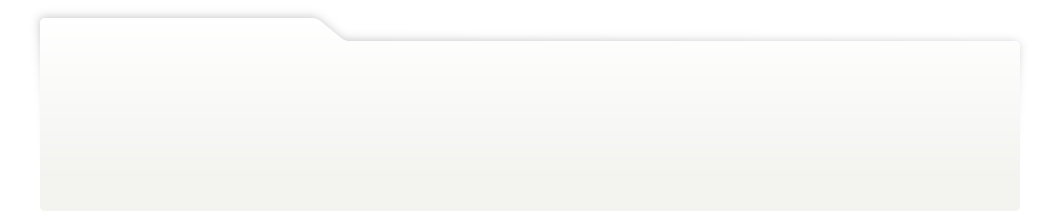
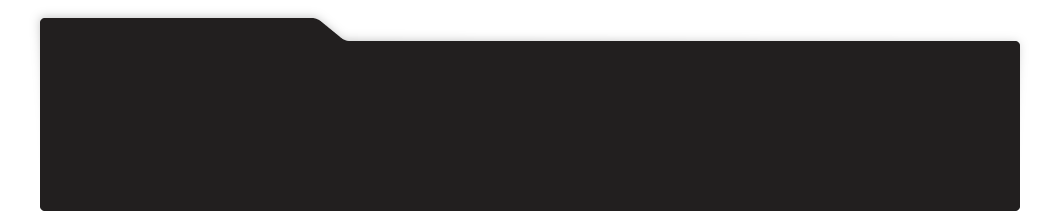
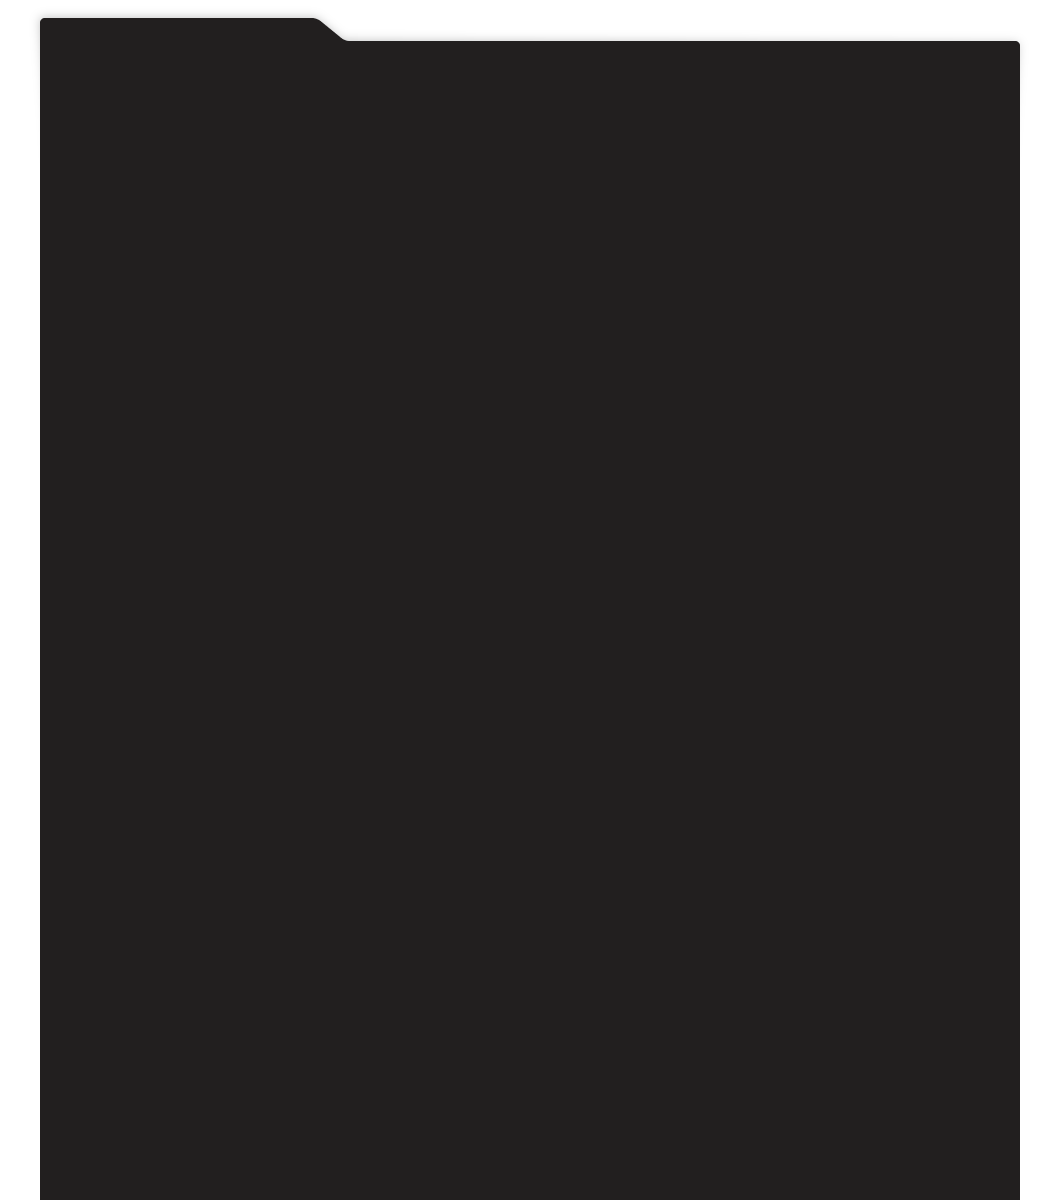
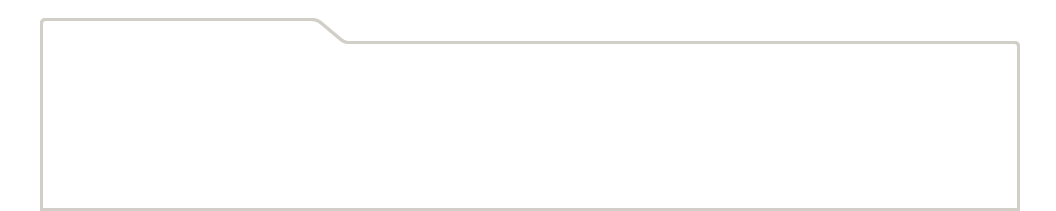
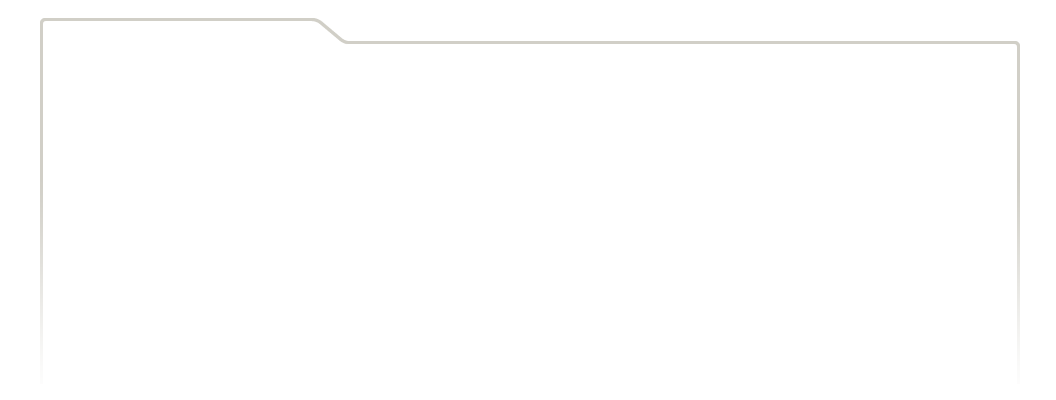
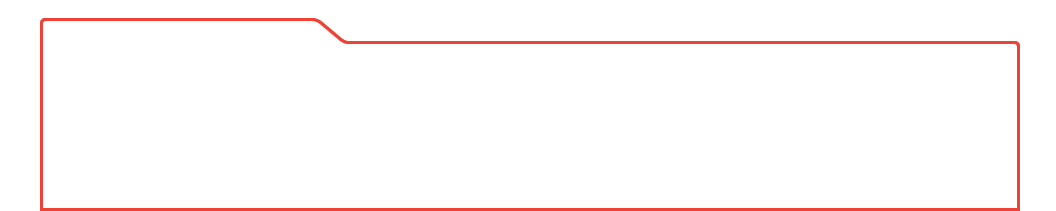
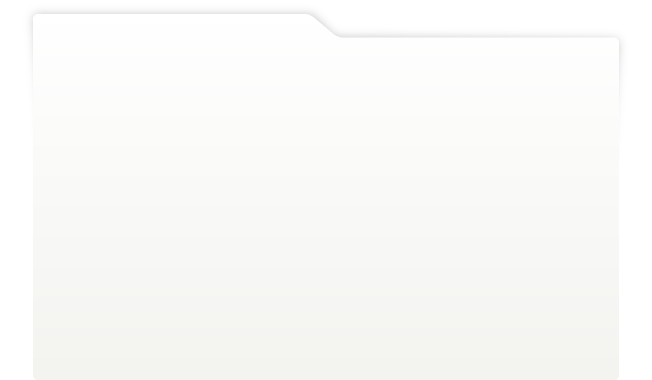
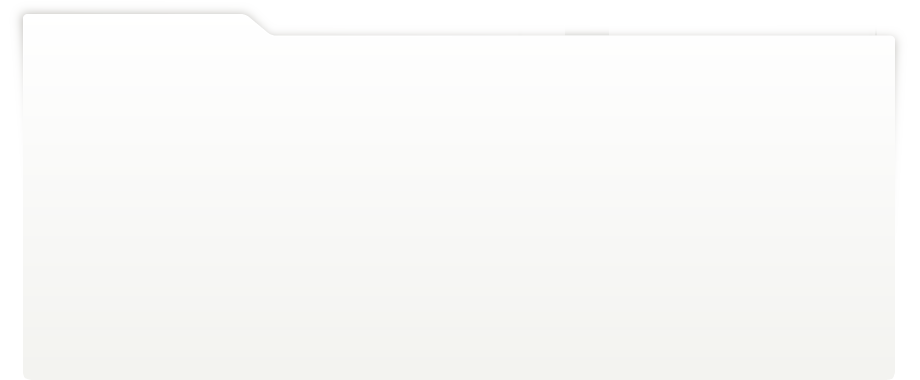
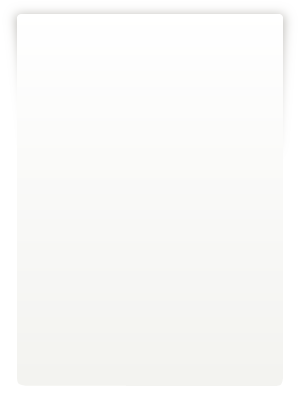
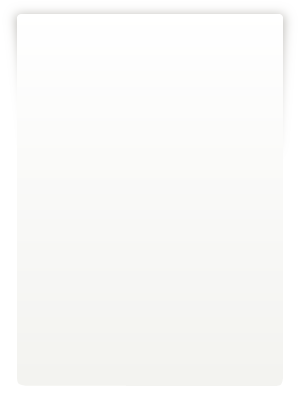
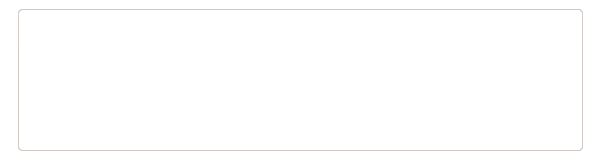
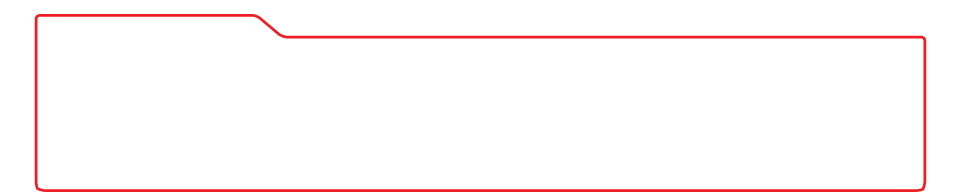
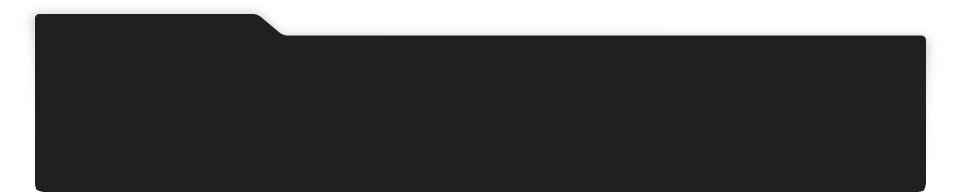
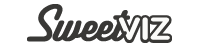
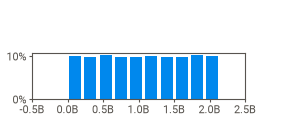
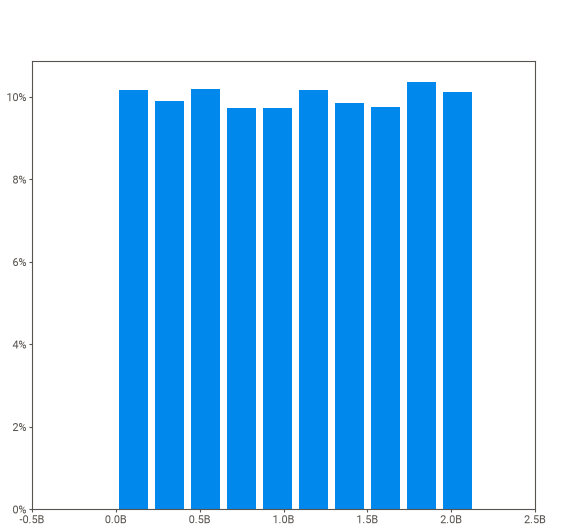
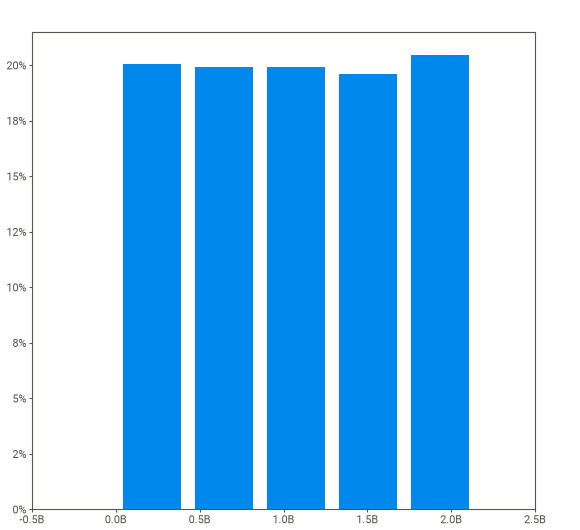
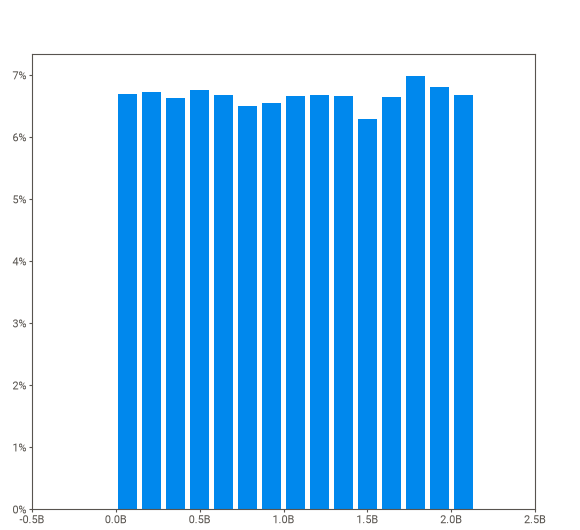
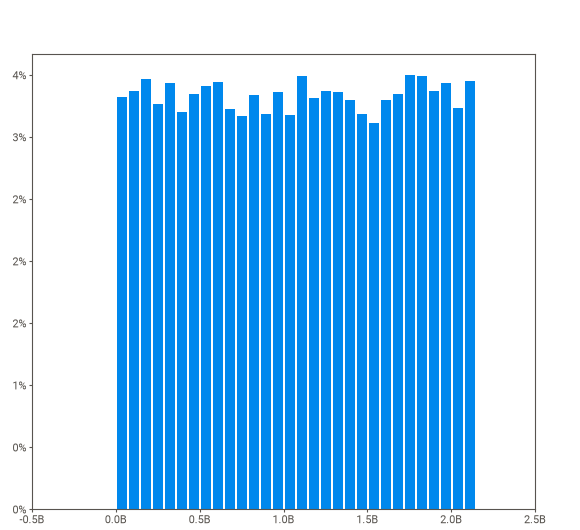
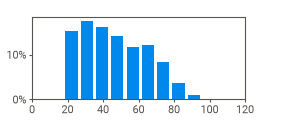
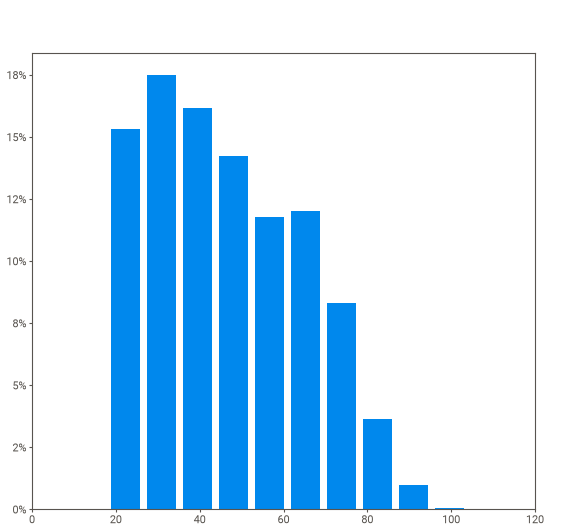
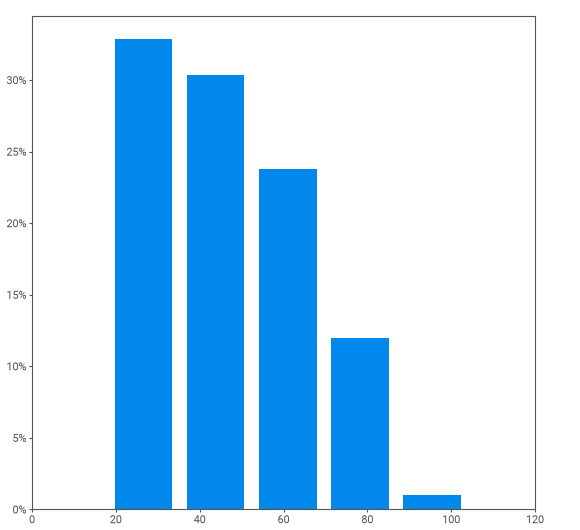
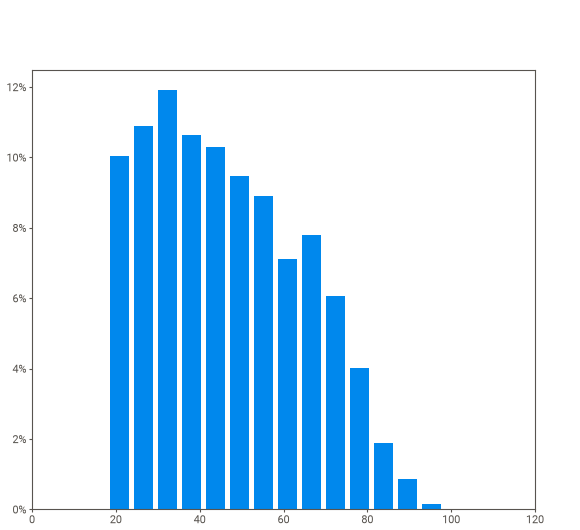
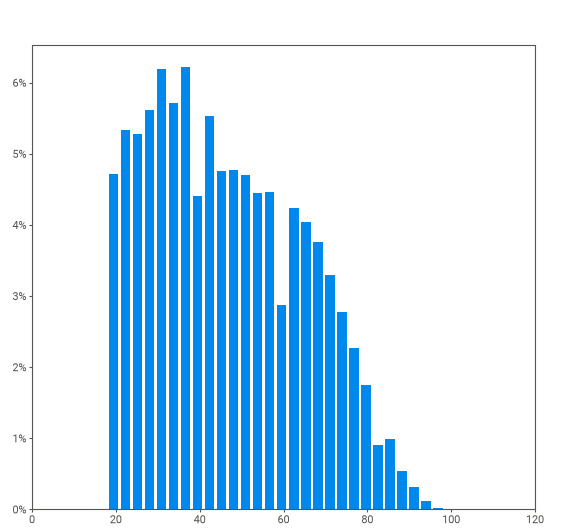
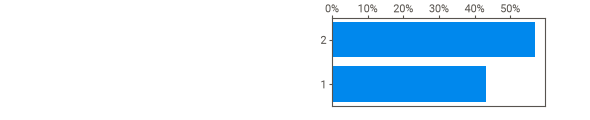
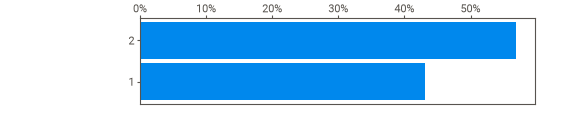
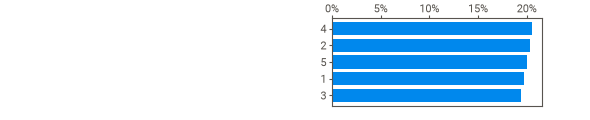
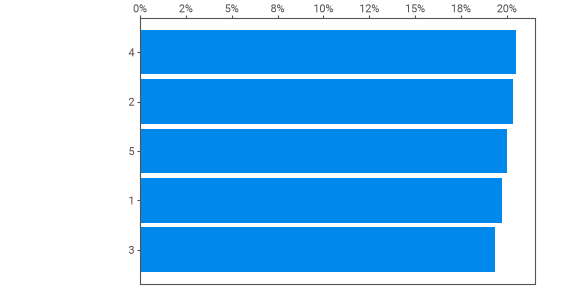
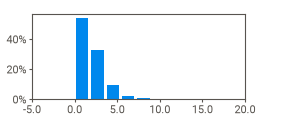
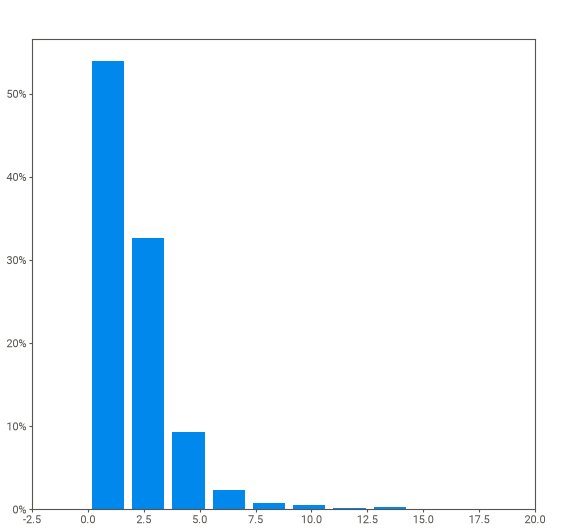
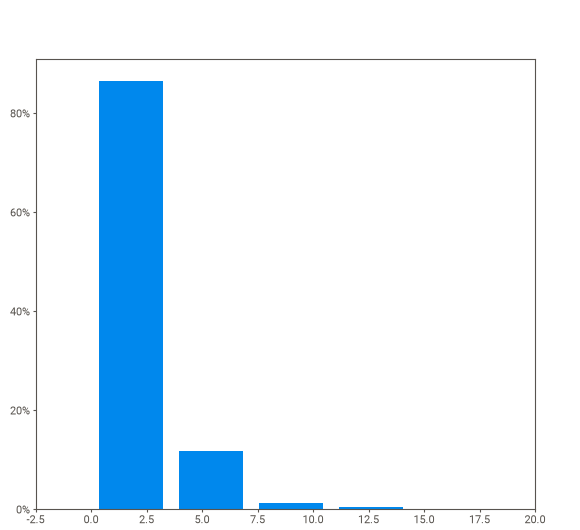
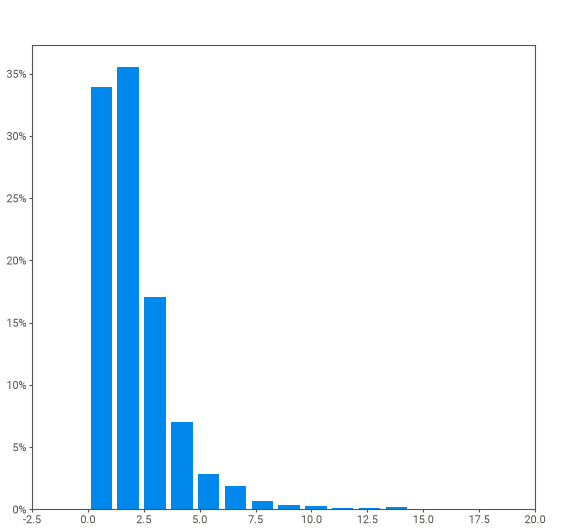
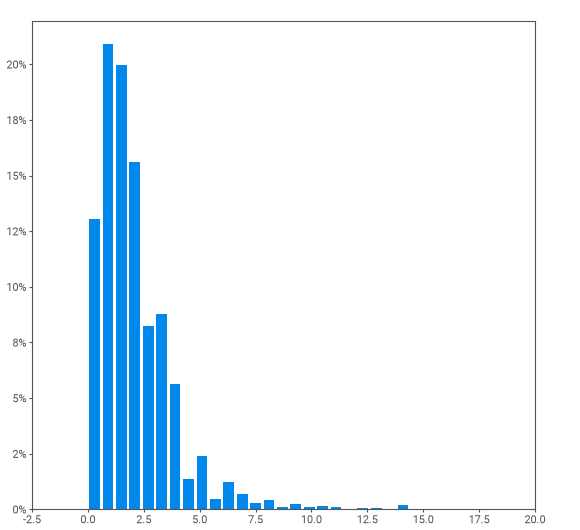
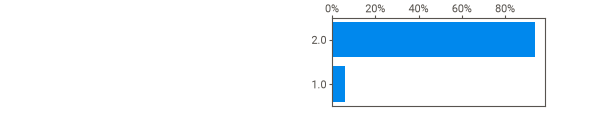
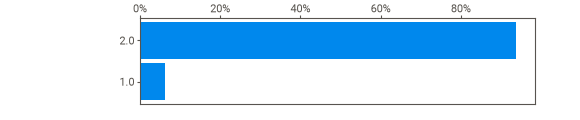
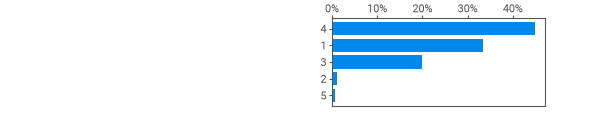
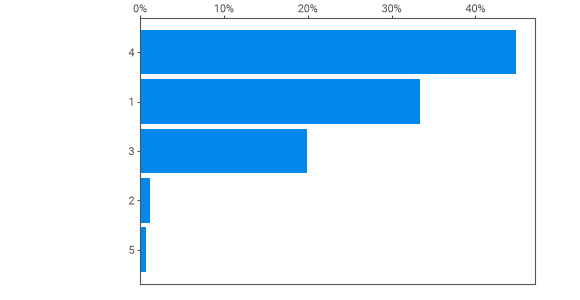
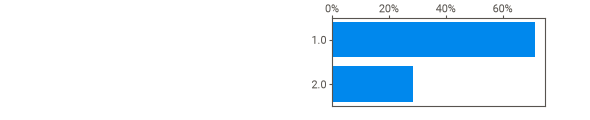
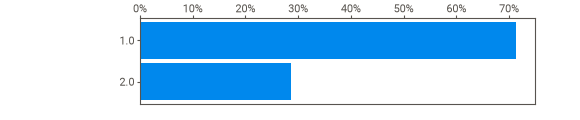
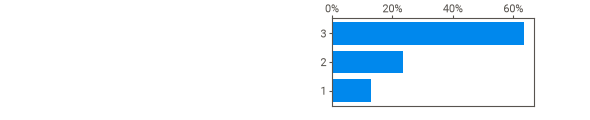
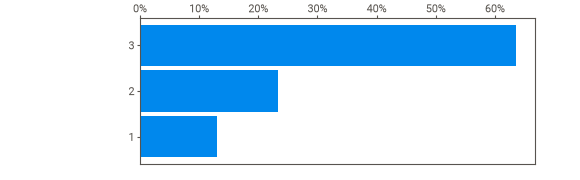
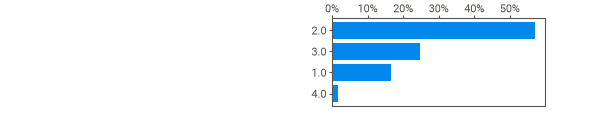
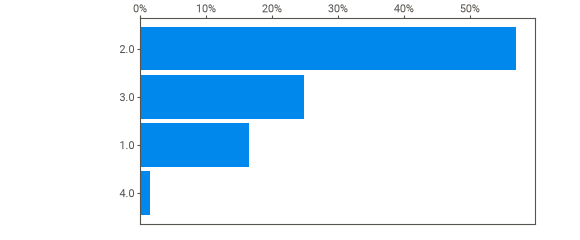
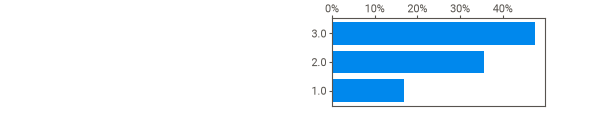
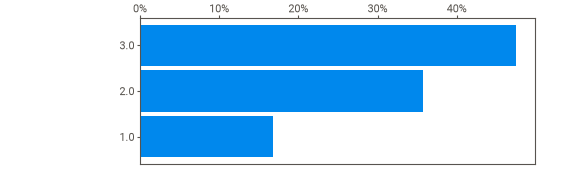
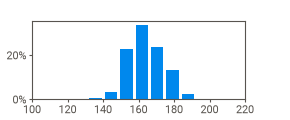
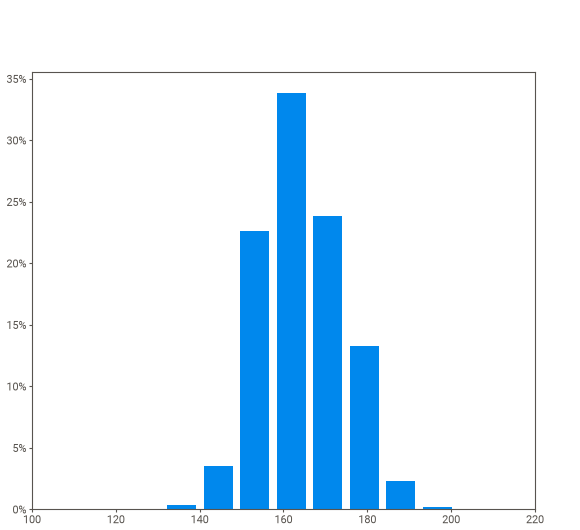
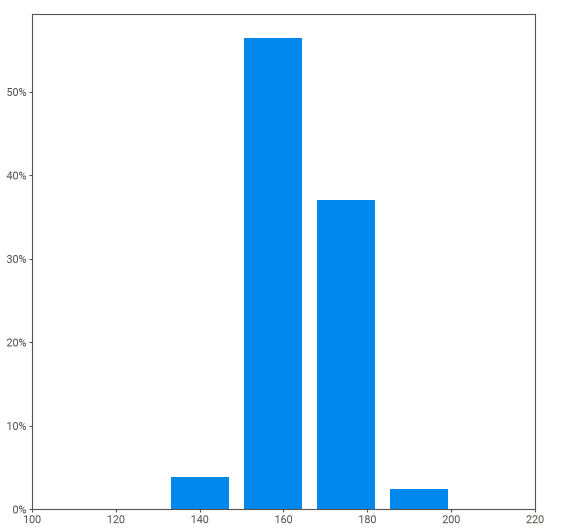
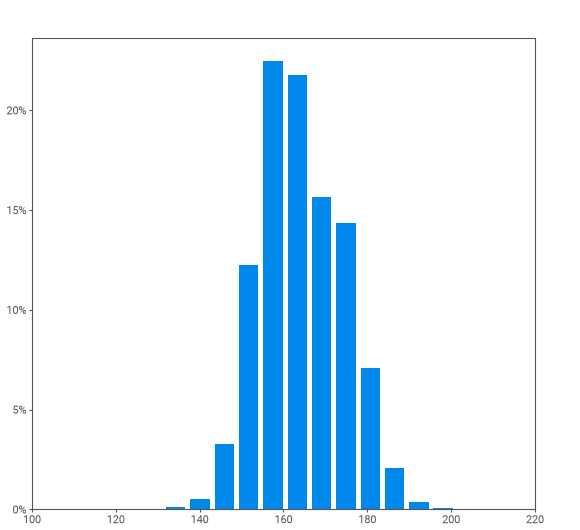
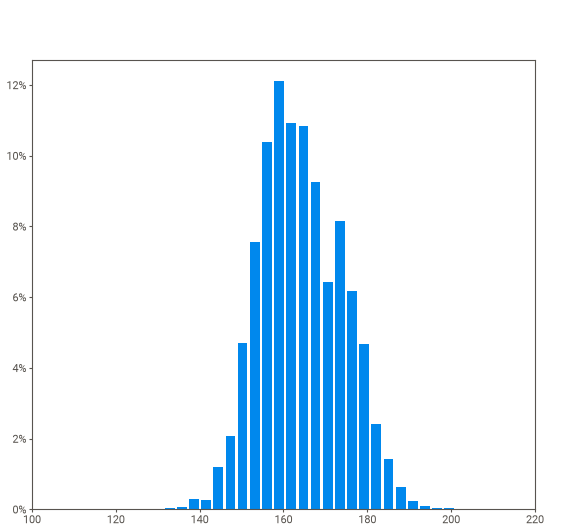
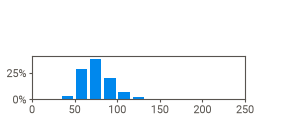
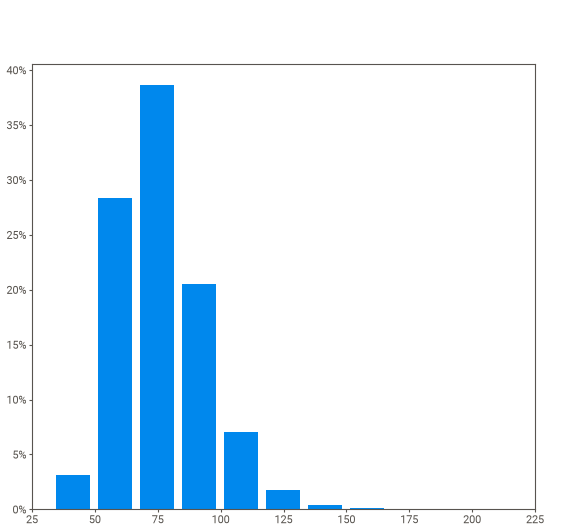
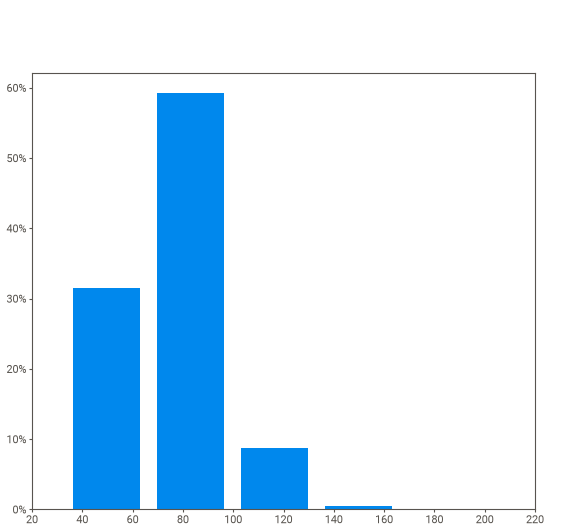
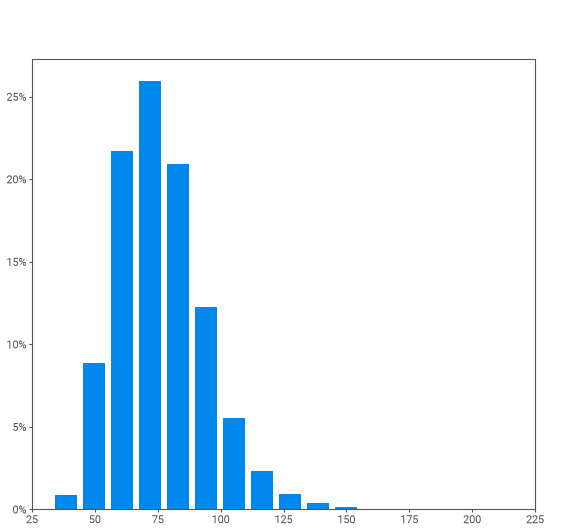
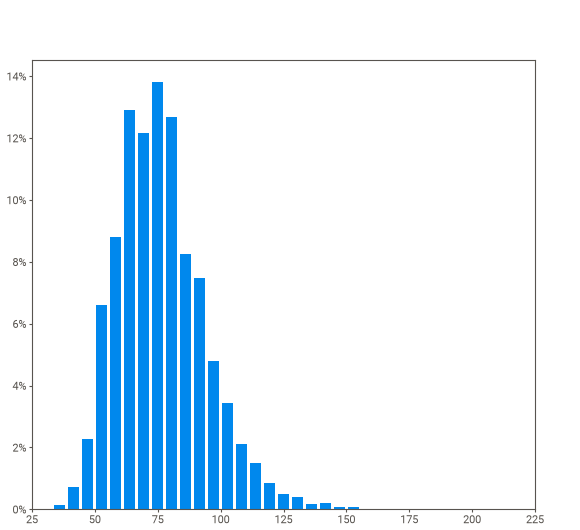
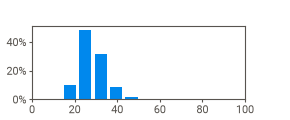
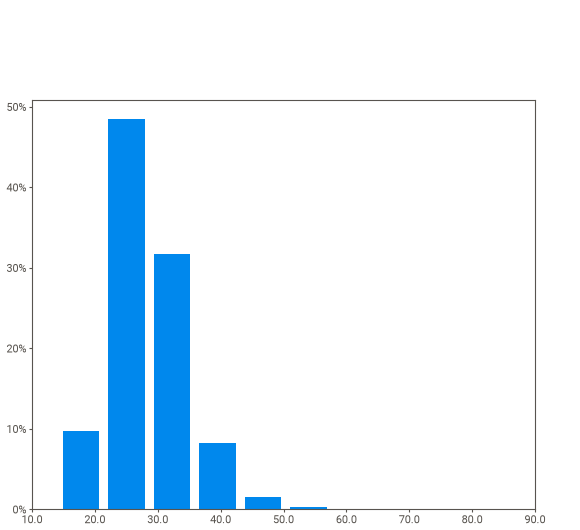
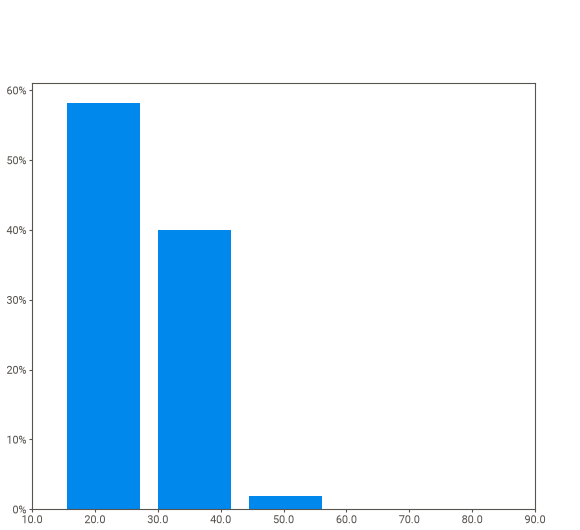
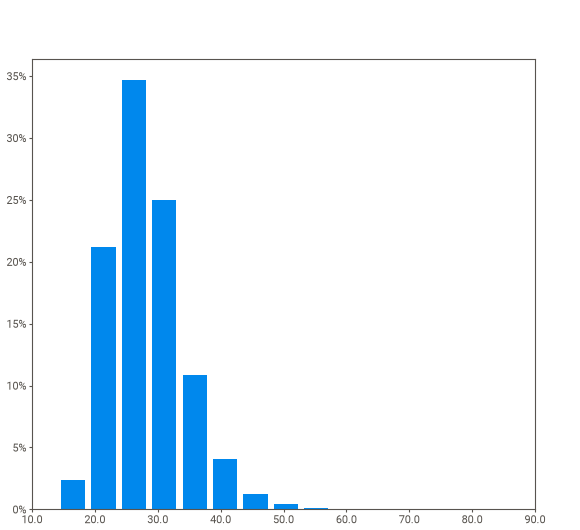
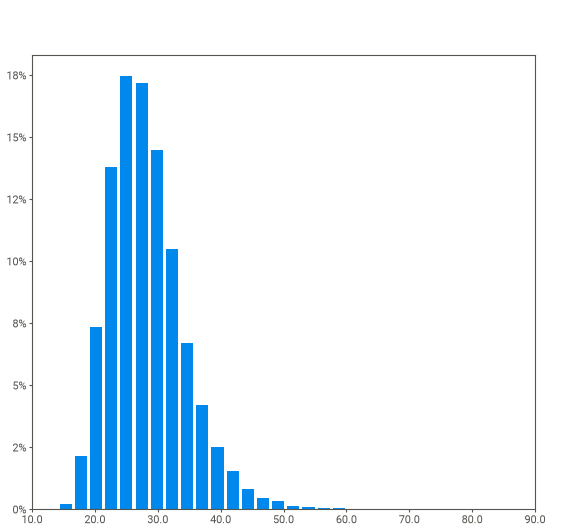
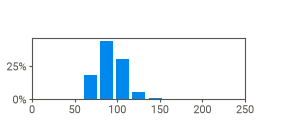
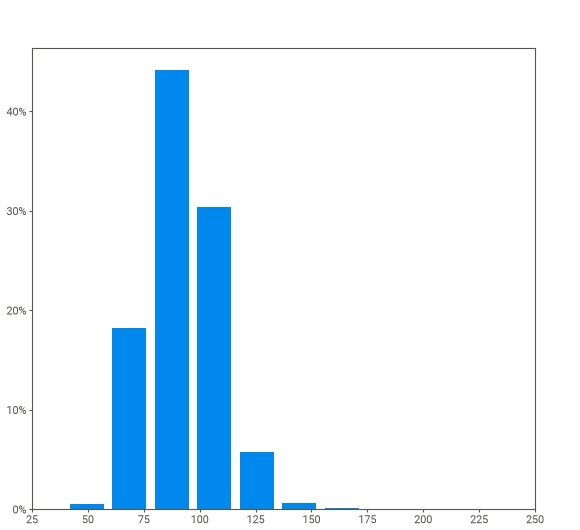
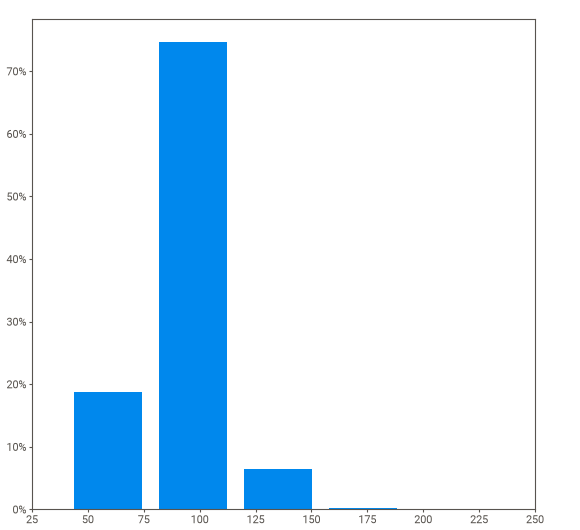
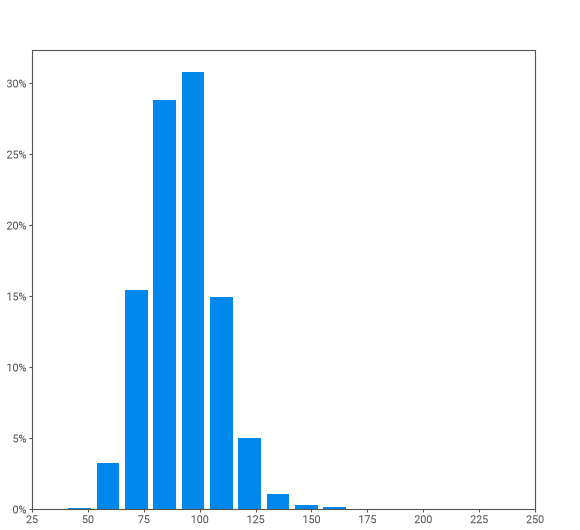
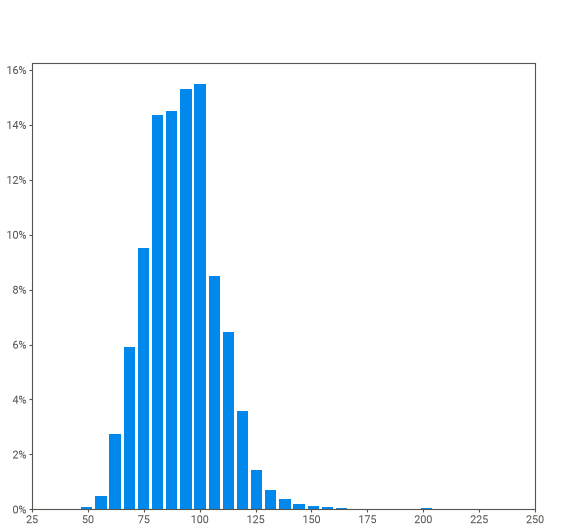
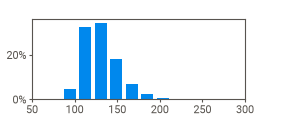
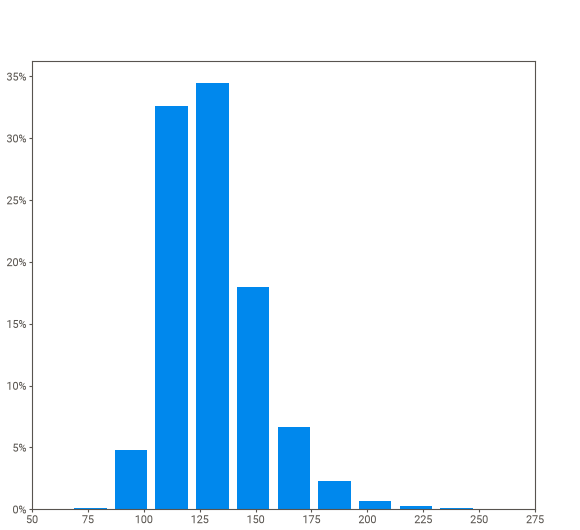
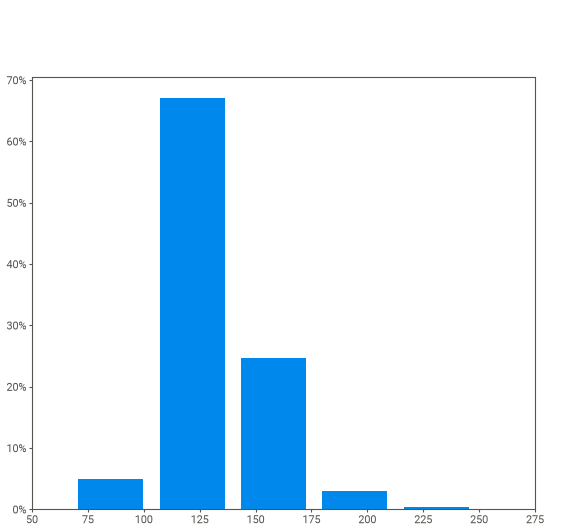
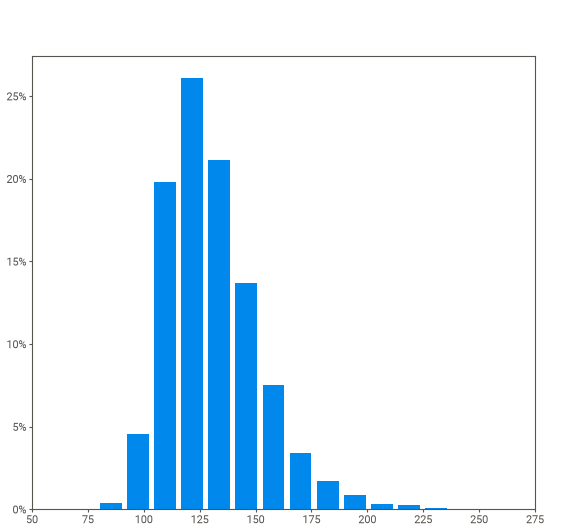
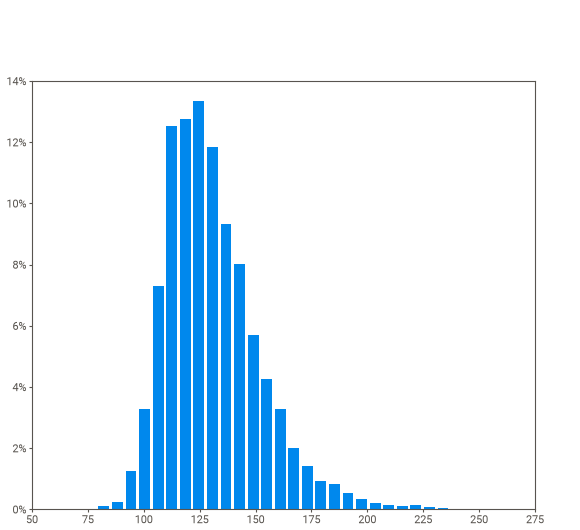
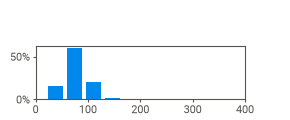
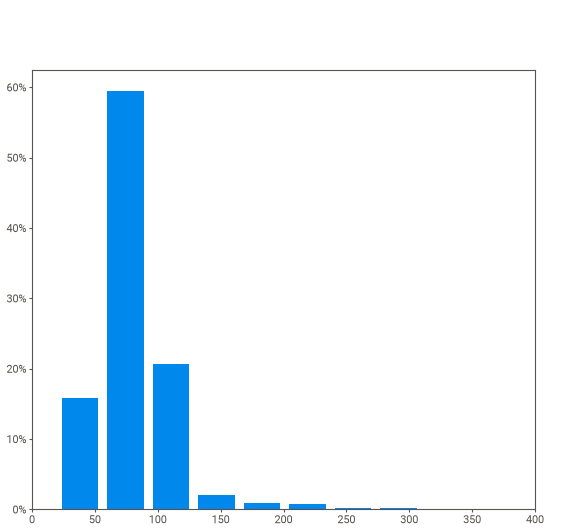
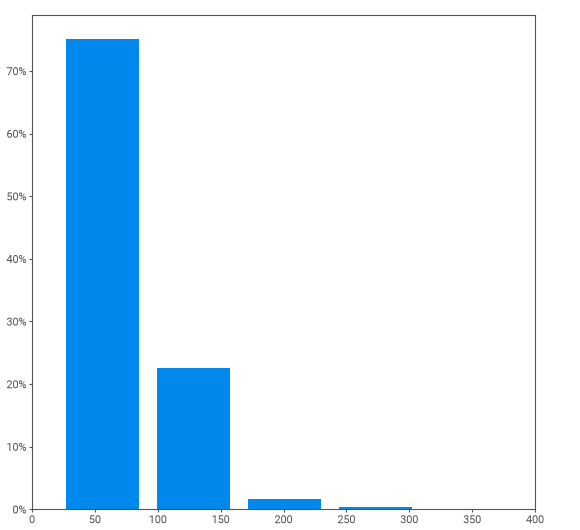
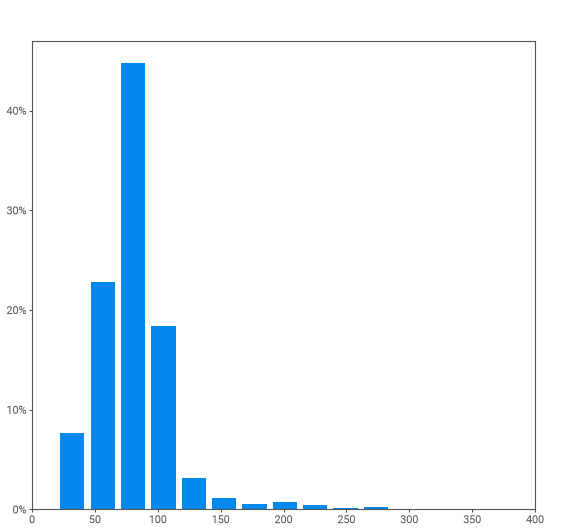
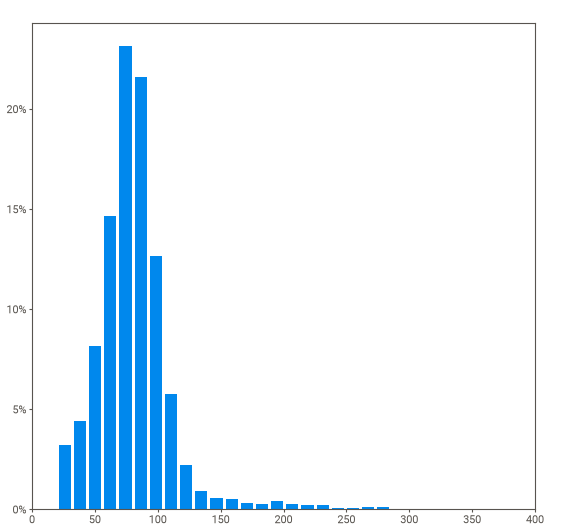
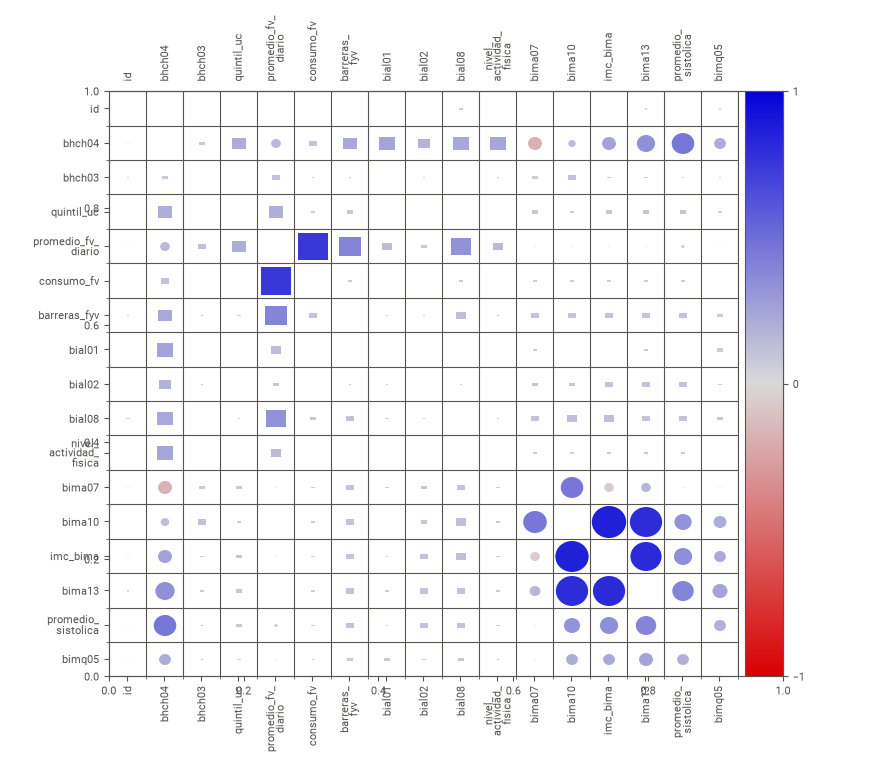
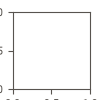

In [49]:
preprocessed_dataset = preprocessed_dataset.replace({pd.NA: np.nan})
reporte = sv.analyze(preprocessed_dataset)
reporte.show_notebook()

### Analisis de nulos
Cantidad de NaNs(celdas vacias) por variable

In [24]:
raw_dataset.isna().sum()

id                            0
bhch04                        0
bhch03                        0
quintil_uc                    0
promedio_fv_diario          753
consumo_fv                    0
barreras_fyv                  0
bial01                        0
bial02                        0
bial08                        0
nivel_actividad_fisica      254
bima07                    12733
bima10                    12799
imc_bima                  12814
bima13                    12912
promedio_sistolica        12997
bimq05                    24036
dtype: int64

Busqueda de nulos(99)

In [ ]:
print(raw_dataset["consumo_fv"].value_counts())
print("---")
print(raw_dataset["bial01"].value_counts())
print("---")
print(raw_dataset["bial08"].value_counts())
print("---")
print(raw_dataset["nivel_actividad_fisica"].value_counts())

bimq05
78.0     129
75.0     125
86.0     123
79.0     123
82.0     120
        ... 
234.0      1
377.0      1
176.0      1
290.0      1
219.0      1
Name: count, Length: 215, dtype: int64
---
consumo_fv
2     26699
1      1772
99      753
Name: count, dtype: int64
---
bial01
1     20780
2      8346
99       98
Name: count, dtype: int64
---
bial08
2     16622
3      7248
1      4824
4       451
99       79
Name: count, dtype: int64
---
nivel_actividad_fisica
3.0    13764
2.0    10347
1.0     4859
Name: count, dtype: int64


### Conversion de 99 a NaNs

La base de datos del indec usa el 99, 999 y el 9999 como valores de identificacion de nulos. Luego de analizar nuestras variables seleccionadas nos damos cuenta que solo se utiliza el 99 en estas, por lo tanto no tomamos en cuenta los otros 2.

In [44]:
preprocessed_dataset = raw_dataset.copy()

preprocessed_dataset['consumo_fv'] = preprocessed_dataset['consumo_fv'].replace(99, pd.NA)
preprocessed_dataset['bial01'] = preprocessed_dataset['bial01'].replace(99, pd.NA)
preprocessed_dataset['bial08'] = preprocessed_dataset['bial08'].replace(99, pd.NA)
preprocessed_dataset['nivel_actividad_fisica'] = preprocessed_dataset['nivel_actividad_fisica'].replace(99, pd.NA)

preprocessed_dataset.isna().sum()

id                            0
bhch04                        0
bhch03                        0
quintil_uc                    0
promedio_fv_diario          753
consumo_fv                  753
barreras_fyv                  0
bial01                       98
bial02                        0
bial08                       79
nivel_actividad_fisica      254
bima07                    12733
bima10                    12799
imc_bima                  12814
bima13                    12912
promedio_sistolica        12997
bimq05                    24036
dtype: int64

### Calculo de porcentaje de nulos
Utilizado para seleccionar la mejor tecnica de tratamiento de nulos

In [47]:
vars_tpe = ["bhch04", "bhch03", "quintil_uc", "promedio_fv_diario", "consumo_fv", "barreras_fyv",
            "bial01", "bial02", "bial08", "nivel_actividad_fisica",
            "bima07", "bima10", "imc_bima", "bima13", "promedio_sistolica", "bimq05"]

nulos_tpe = pd.DataFrame({
    "nulos": preprocessed_dataset[vars_tpe].isna().sum(),
    "porcentaje": (preprocessed_dataset[vars_tpe].isna().mean() * 100).round(2),
}).sort_values("porcentaje", ascending=False)
nulos_tpe

,nulos,porcentaje
bimq05,24036,82.25
promedio_sistolica,12997,44.47
bima13,12912,44.18
imc_bima,12814,43.85
bima10,12799,43.80
bima07,12733,43.57
promedio_fv_diario,753,2.58
consumo_fv,753,2.58
nivel_actividad_fisica,254,0.87
bial01,98,0.34


## Detecion de outliers

In [ ]:
vars_cuantitativas = [
    "bhch04", "promedio_fv_diario", "bima07", "bima10",
    "imc_bima", "bima13", "promedio_sistolica", "bimq05"
]

Q1 = preprocessed_dataset[vars_cuantitativas].quantile(0.25)
Q3 = preprocessed_dataset[vars_cuantitativas].quantile(0.75)
IQR = Q3 - Q1

outliers = (preprocessed_dataset[vars_cuantitativas] < (Q1 - 1.5 * IQR)) | (preprocessed_dataset[vars_cuantitativas] > (Q3 + 1.5 * IQR))

tabla_outliers = pd.DataFrame({
    "Cantidad de Outliers": outliers.sum(),
    "Porcentaje (%)": (outliers.mean() * 100).round(2),
    "Presencia de Outliers": outliers.sum() > 0
})

tabla_outliers

,Cantidad de Outliers,Porcentaje (%),Presencia de Outliers
bhch04,0,0.00,False
promedio_fv_diario,1206,4.13,True
bima07,41,0.14,True
bima10,301,1.03,True
imc_bima,343,1.17,True
bima13,170,0.58,True
promedio_sistolica,456,1.56,True
bimq05,251,0.86,True


## Analisis de Correlacion de pearson

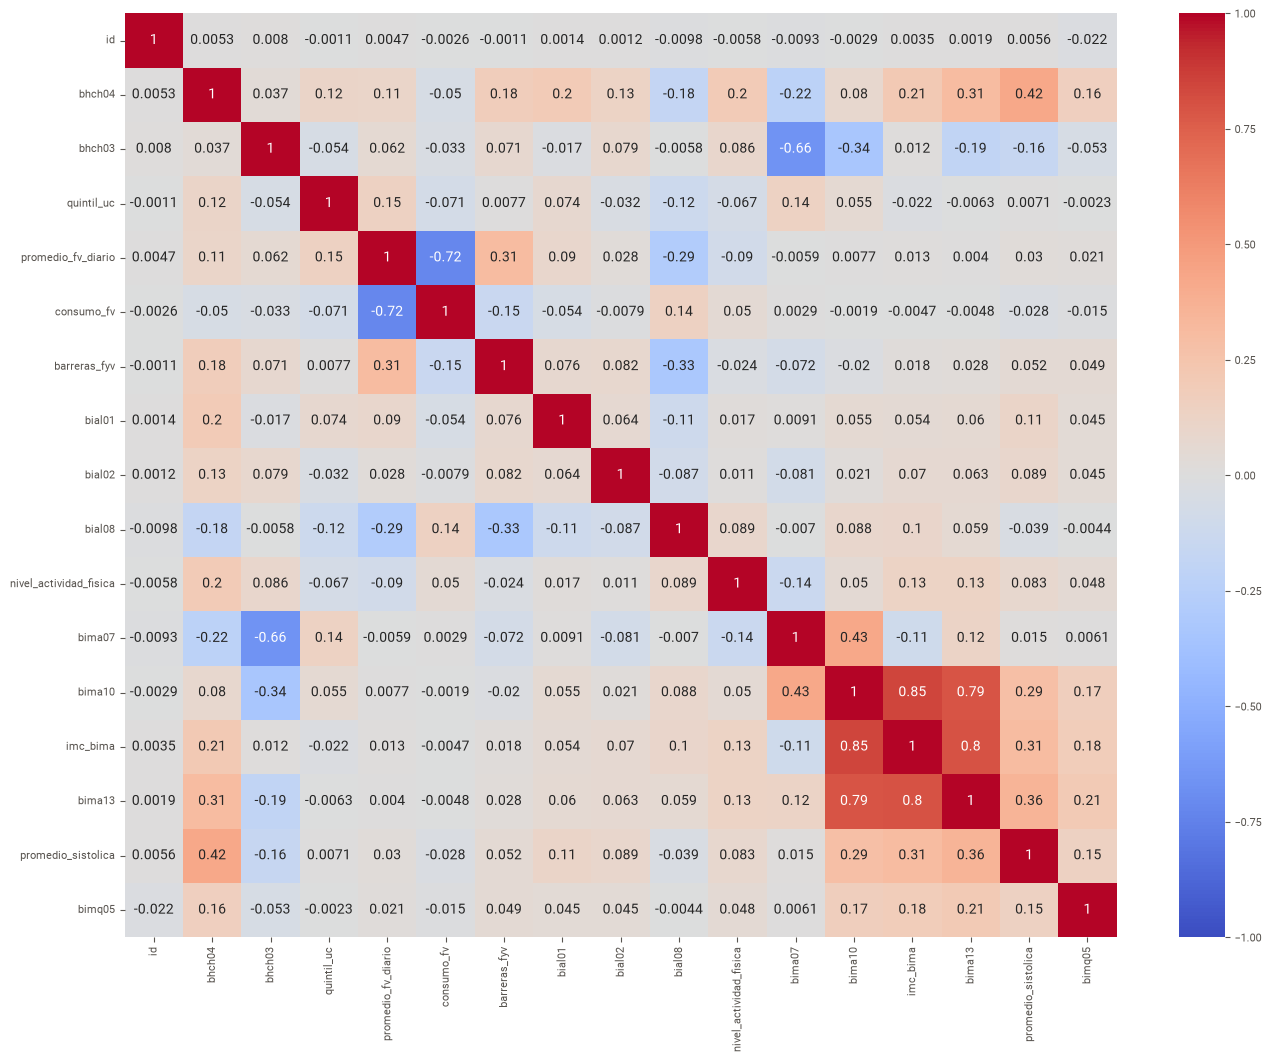

In [59]:
correlation_matrix = preprocessed_dataset.corr()

plt.figure(figsize=(16,12))
sns.heatmap(correlation_matrix, vmin=-1.0, vmax=1.0, center=0.0, annot=True, cmap= 'coolwarm')
plt.show() 